In [1]:
import random
import matplotlib.pyplot as plt
from ultralytics import YOLO

In [3]:
import sys
sys.path.append("..")

In [4]:
from src.config import YOLO_DIR, MODELS_DIR, CLASS_NAMES, IMAGE_EXTS, SEED
from src.data_utils import read_label
from src.visualise import draw_boxes

In [5]:
IMG_DIR = YOLO_DIR / "images" / "test"
LBL_DIR = YOLO_DIR / "labels" / "test"
NAME_TO_ID = {name: cid for cid, name in CLASS_NAMES.items()}

model = YOLO(str(MODELS_DIR / "final_yolo11n_960.pt"))
images = {f.stem: f for f in IMG_DIR.iterdir() if f.suffix.lower() in IMAGE_EXTS}

In [6]:
def stems_with_class(class_name):
    """Test images whose label file contains at least one box of this class."""
    cid = NAME_TO_ID[class_name]
    return sorted(
        p.stem for p in LBL_DIR.glob("*.txt")
        if any(b["class_id"] == cid for b in read_label(p))
    )

In [9]:
def show_pair(stem, class_name):
    cid = NAME_TO_ID[class_name]
    img_path = images[stem]
    lbl_path = LBL_DIR / f"{stem}.txt"

    gt = draw_boxes(img_path, lbl_path)  # ground truth, already RGB
    res = model.predict(str(img_path), imgsz=960, conf=0.10, device=0, verbose=False)[0]
    pred = res.plot()[:, :, ::-1]        # model output, BGR -> RGB

    n_gt = sum(b["class_id"] == cid for b in read_label(lbl_path))
    n_pred = int((res.boxes.cls == cid).sum())

    fig, axes = plt.subplots(1, 2, figsize=(14, 6))
    axes[0].imshow(gt)
    axes[0].set_title(f"Ground truth: {n_gt} {class_name}")
    axes[1].imshow(pred)
    axes[1].set_title(f"Predicted: {n_pred} {class_name}")
    for ax in axes:
        ax.axis("off")
    fig.suptitle(stem, fontsize=10)
    plt.tight_layout()
    plt.show()

safety-vest -> 30 test images; picked: ['pexels-photo-8853513', 'pexels-photo-8155814', 'pexels-photo-19087917']
helmet -> 78 test images; picked: ['pexels-photo-5013577', 'pexels-photo-18548771', 'pexels-photo-18110372']


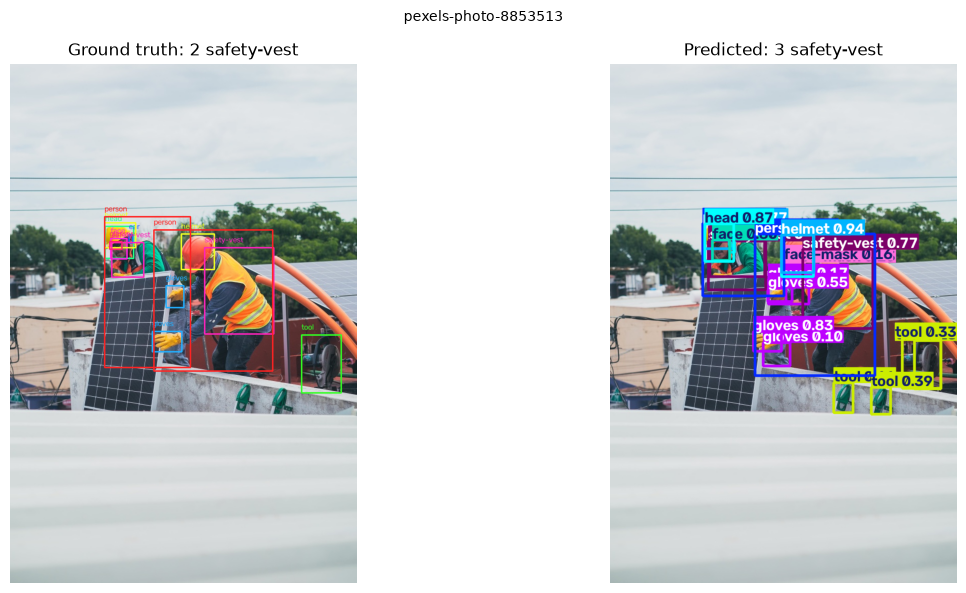

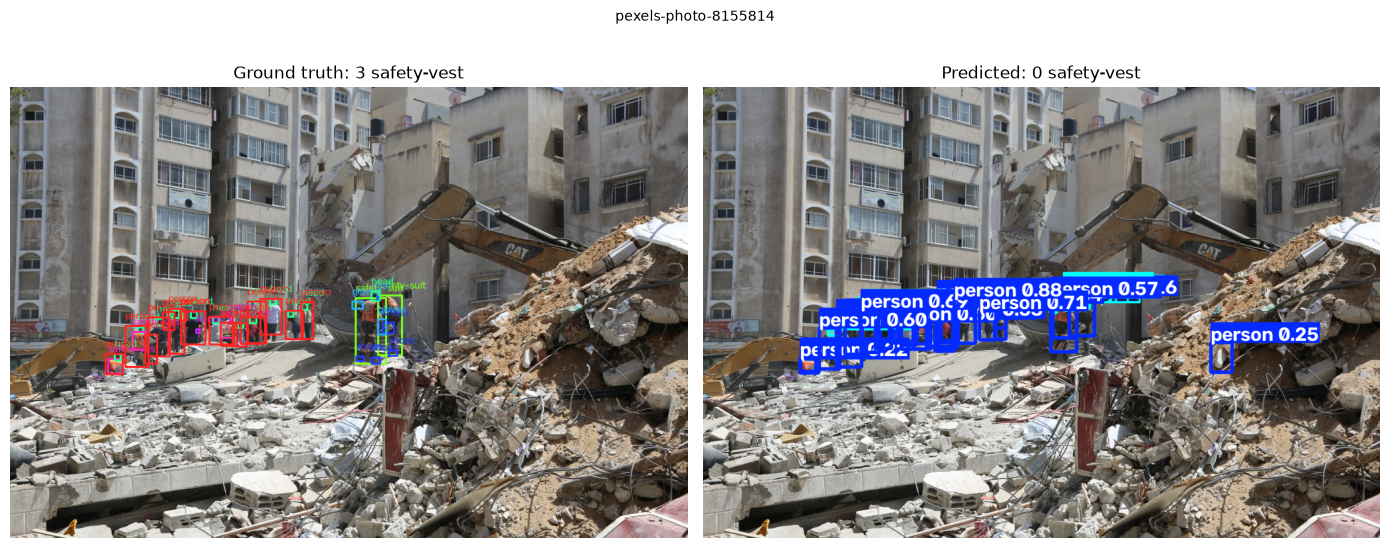

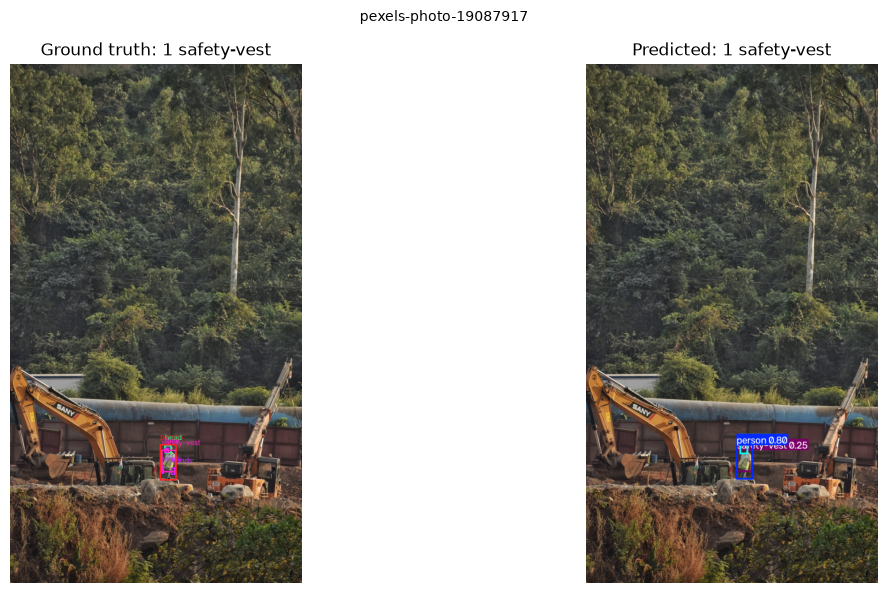

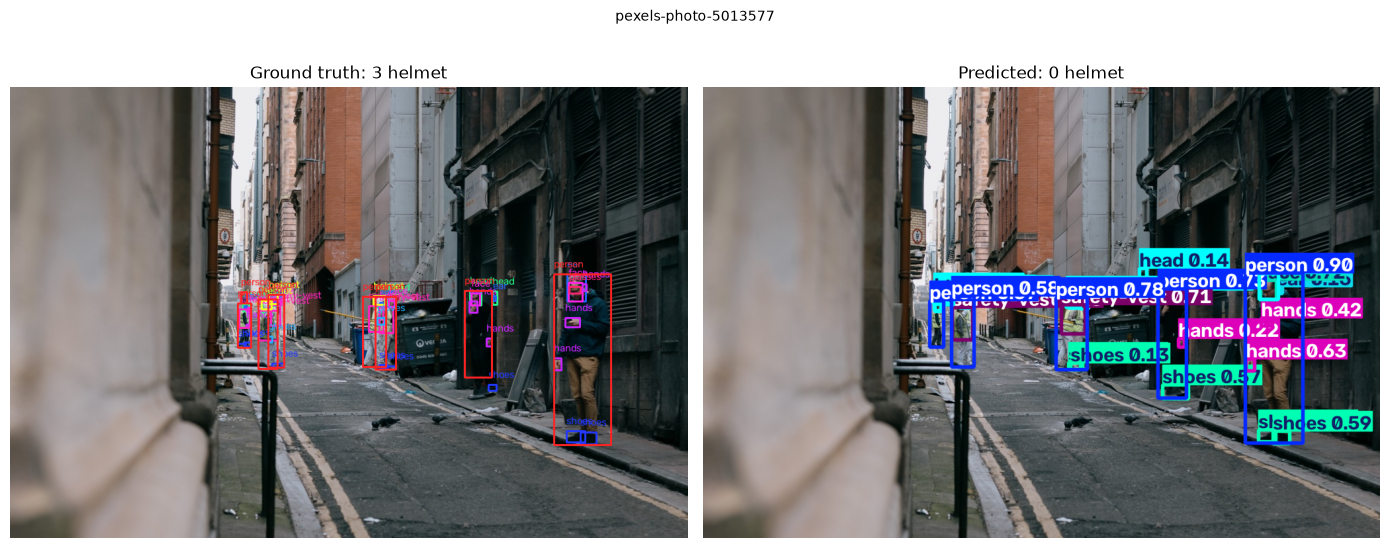

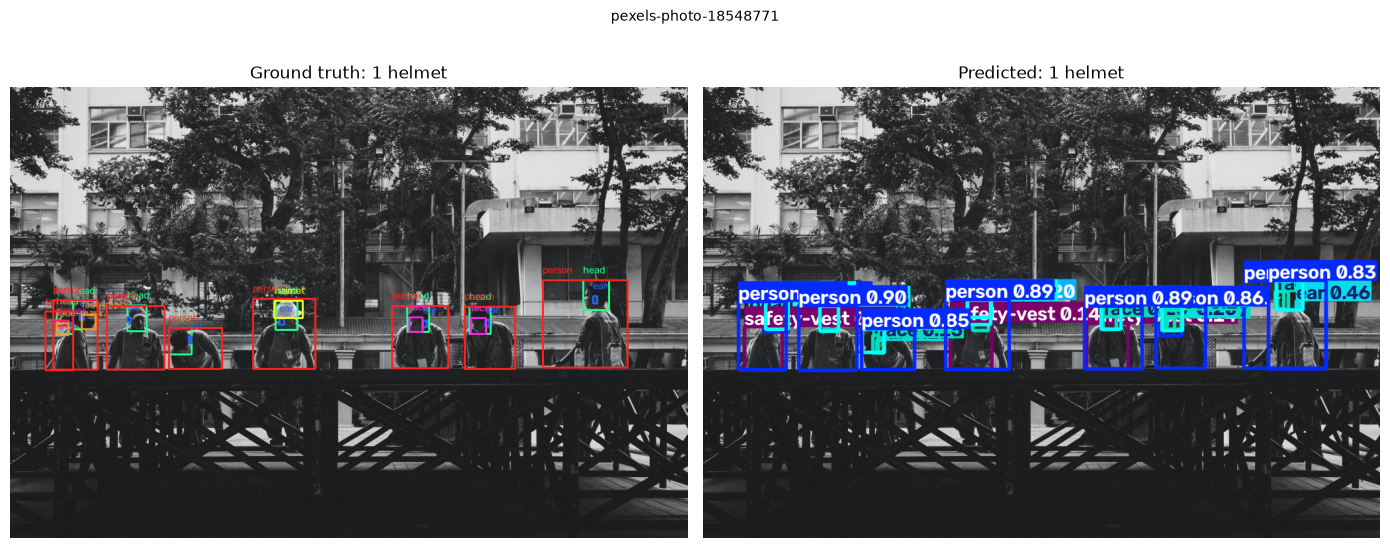

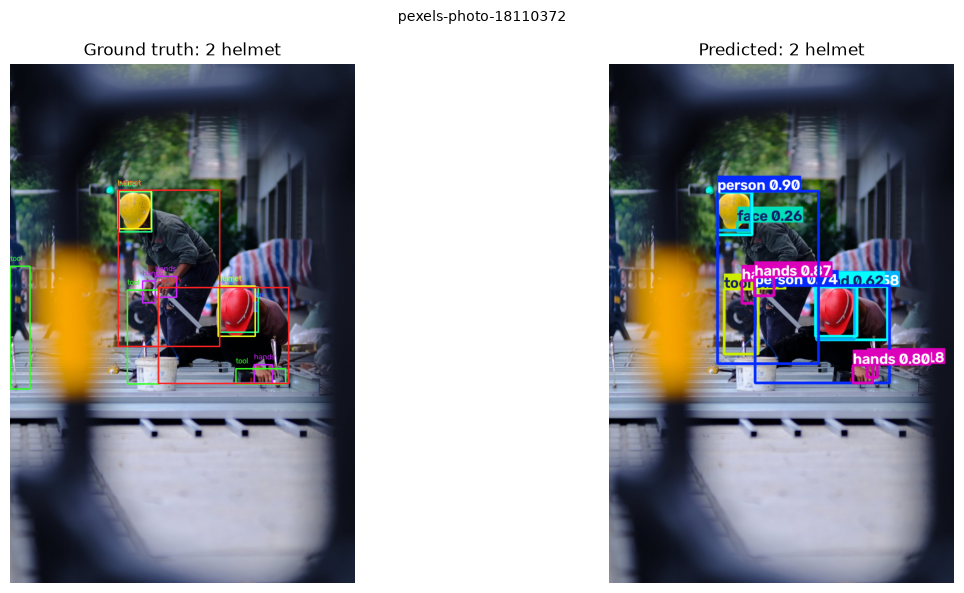

In [10]:
rng = random.Random(SEED)
picks = {}
for cname in ["safety-vest", "helmet"]:
    candidates = stems_with_class(cname)
    picks[cname] = rng.sample(candidates, 3)
    print(cname, "->", len(candidates), "test images; picked:", picks[cname])

for cname, stems in picks.items():
    for s in stems:
        show_pair(s, cname)